<a href="https://colab.research.google.com/github/CRM48/AIML425-A4/blob/main/GaussianToDogsSDE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step    0 | mean t=0.51 | Loss=1.07135
Step  500 | mean t=0.52 | Loss=0.13528
Step 1000 | mean t=0.53 | Loss=0.15461
Step 1500 | mean t=0.45 | Loss=0.16329
Step 2000 | mean t=0.51 | Loss=0.09486
Step 2500 | mean t=0.51 | Loss=0.11462
Step 3000 | mean t=0.51 | Loss=0.10140
Step 3500 | mean t=0.53 | Loss=0.08637
Step 4000 | mean t=0.50 | Loss=0.11129
Step 4500 | mean t=0.53 | Loss=0.07820


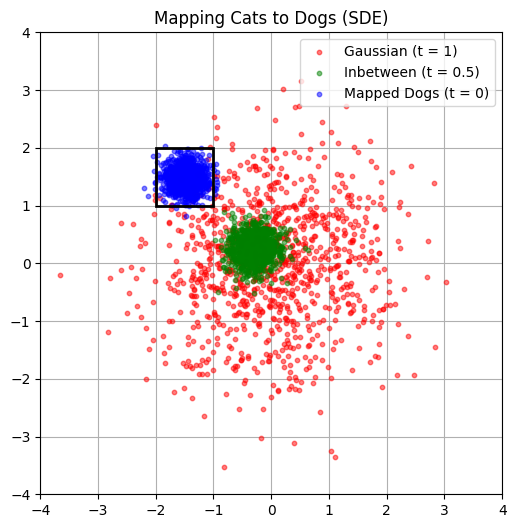

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

device = "cpu"

# Samples

def sample_dogs(n=1000):
    np_samples = np.random.uniform(low=[-2, 1], high=[-1, 2], size=(n, 2))
    return torch.tensor(np_samples, dtype=torch.float32)

def sample_gaussians(n=1000, s=1.0):
    np_samples = np.random.normal(loc=0.0, scale=np.sqrt(s), size=(n, 2))
    return torch.tensor(np_samples, dtype=torch.float32)

# Forward process

T_final = 1.0
BETA_MIN = 0.1
BETA_MAX = 20.0


def alpha_sigma_coeffs(t):
    integral_beta = BETA_MIN * t + 0.5 * (BETA_MAX - BETA_MIN) * t**2
    alpha_t = torch.exp(-0.5 * integral_beta)
    sigma_t = torch.sqrt(1.0 - torch.exp(-integral_beta))
    sigma_t = torch.clamp(sigma_t, min=1e-5)
    return alpha_t, sigma_t


def forward_sde_step(x0, t):
    alpha_t, sigma_t = alpha_sigma_coeffs(t)
    alpha_t_r = alpha_t.view(-1, 1)
    sigma_t_r = sigma_t.view(-1, 1)

    epsilon = torch.randn_like(x0)
    x_t = alpha_t_r * x0 + sigma_t_r * epsilon
    return x_t

# Model

class ScoreNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2+1, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x, t):
        xt = torch.cat([x, t], dim=1)
        return self.net(xt)


# Training

model = ScoreNet().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)


n_steps = 5000
batch_size = 128

for step in range(n_steps):
    x0 = sample_dogs(batch_size).to(device)
    t_batch = torch.rand(batch_size, 1).to(device)

    x_t = forward_sde_step(x0, t_batch)
    _, sigma_t = alpha_sigma_coeffs(t_batch)

    true_score = -(x_t - alpha_sigma_coeffs(t_batch)[0]*x0) / sigma_t
    pred_score = model(x_t, t_batch)

    weight = 1
    loss = (weight * (pred_score - true_score)**2).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if step % 500 == 0:
        print(f"Step {step:4d} | mean t={t_batch.mean().item():.2f} | Loss={loss.item():.5f}")


# Reverse SDE

x_start = sample_gaussians(1000)
x = x_start.clone()

num_steps = 100
dt = 1.0 / num_steps

"""
NOTE: the equation used below is a very much adapted euler maruyama
Using the actual version with my alpha_sigma_coeffs function inflated the
values significantly

This was the part that I predict works the worst, I tested the model and
it appears to produce proper scores
"""
for i in range(num_steps):
    t_i = torch.full((x.shape[0], 1), 1.0 - i*dt)
    s_theta = model(x, t_i)
    noise = torch.randn_like(x)
    x = x + s_theta * math.sqrt(dt) + noise * math.sqrt(dt)
    if(i == num_steps/2):
      x_middle = x.detach().cpu()

x_end = x.detach().cpu()

plt.figure(figsize=(6,6))
plt.scatter(x_start[:,0].cpu(), x_start[:,1].cpu(), alpha=0.5, color='red', s=10, label='Gaussian (t = 1)')
plt.scatter(x_middle[:,0].cpu(), x_middle[:,1].cpu(), alpha=0.5, color='green', s=10, label='Inbetween (t = 0.5)')
plt.scatter(x_end[:,0], x_end[:,1], alpha=0.5, color='blue', s=10, label='Mapped Dogs (t = 0)')

rect = patches.Rectangle((-2, 1), 1, 1, linewidth=2, edgecolor='black', facecolor='none')
plt.gca().add_patch(rect)

plt.xlim(-4, 4)
plt.ylim(-4, 4)
plt.gca().set_aspect('equal')
plt.legend(loc='upper right')
plt.title("Mapping Cats to Dogs (SDE)")
plt.grid(True)
plt.gca().set_axisbelow(True)
plt.show()